In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from features import load_grid, build_table

grid, capacity = load_grid("../data/historical/station_status.parquet")
df = build_table(grid, capacity)
print("Rows:", f"{len(df):,}")
df.head()

Rows: 3,856,648


,slot,station_id,bikes_now,bikes_future,change_last_15min,change_last_30min,change_last_60min,hour,minute,dayofweek,capacity,fill_ratio,change
0,2025-07-01 00:00:00+00:00,1,0.0,0.0,NaN,NaN,NaN,1,30,1,31,0.0,0.0
1,2025-07-01 00:15:00+00:00,1,0.0,0.0,0.0,NaN,NaN,1,45,1,31,0.0,0.0
2,2025-07-01 00:30:00+00:00,1,0.0,0.0,0.0,0.0,NaN,2,0,1,31,0.0,0.0
3,2025-07-01 00:45:00+00:00,1,0.0,0.0,0.0,0.0,NaN,2,15,1,31,0.0,0.0
4,2025-07-01 01:00:00+00:00,1,0.0,0.0,0.0,0.0,0.0,2,30,1,31,0.0,0.0


In [2]:
train = df[df["slot"] < pd.Timestamp("2026-03-01", tz="Europe/Dublin")].copy()
valid = df[(df["slot"] >= pd.Timestamp("2026-03-01", tz="Europe/Dublin"))
           & (df["slot"] < pd.Timestamp("2026-04-01", tz="Europe/Dublin"))].copy()
test = df[df["slot"] >= pd.Timestamp("2026-04-01", tz="Europe/Dublin")].copy()

print(f"Train {len(train):,}  Valid {len(valid):,}  Test {len(test):,}")

Train 2,515,959  Valid 340,805  Test 999,884


In [3]:
typical = (train.groupby(["station_id", "dayofweek", "hour"])["change"]
           .mean().rename("typical_change").reset_index())

all_stations = sorted(df["station_id"].unique())
parts = []
for part in (train, valid, test):
    part = part.merge(typical, on=["station_id", "dayofweek", "hour"], how="left")
    part["typical_change"] = part["typical_change"].fillna(0)
    part["station_id"] = pd.Categorical(part["station_id"], categories=all_stations)
    parts.append(part)
train, valid, test = parts

FEATURES = ["station_id", "bikes_now", "capacity", "fill_ratio",
            "change_last_15min", "change_last_30min", "change_last_60min",
            "hour", "minute", "dayofweek", "typical_change"]

In [4]:
model = lgb.LGBMRegressor(
    objective="l1",          # optimise mean absolute error directly
    n_estimators=2000,       # maximum number of trees
    learning_rate=0.05,
    num_leaves=63,
    min_child_samples=100,
    subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8,
    verbose=-1,
)

model.fit(
    train[FEATURES], train["change"],
    eval_set=[(valid[FEATURES], valid["change"])],
    callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)],
)
print("Best number of trees:", model.best_iteration_)

/Users/sam/Documents/dublin-bikes-forecast/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[100]	valid_0's l1: 0.923556
[200]	valid_0's l1: 0.92249
[300]	valid_0's l1: 0.922455
[400]	valid_0's l1: 0.922454
Early stopping, best iteration is:
[359]	valid_0's l1: 0.922453
Best number of trees: 359


In [5]:
test["pred_same_as_now"] = test["bikes_now"]
test["pred_now_plus_change"] = (test["bikes_now"] + test["typical_change"]).clip(lower=0)
test["pred_lightgbm"] = (test["bikes_now"] + model.predict(test[FEATURES])).clip(0, test["capacity"])

actual_empty = test["bikes_future"] == 0
print(f"{'Method':22s} {'MAE':>6s} {'Precision':>10s} {'Recall':>7s}")
for col in ["pred_same_as_now", "pred_now_plus_change", "pred_lightgbm"]:
    mae = (test[col] - test["bikes_future"]).abs().mean()
    predicted_empty = test[col] < 0.5
    caught = (predicted_empty & actual_empty).sum()
    print(f"{col:22s} {mae:6.2f} {caught / predicted_empty.sum():10.0%} {caught / actual_empty.sum():7.0%}")

Method                    MAE  Precision  Recall
pred_same_as_now         1.06        78%     78%
pred_now_plus_change     1.03        78%     78%
pred_lightgbm            0.97        79%     78%


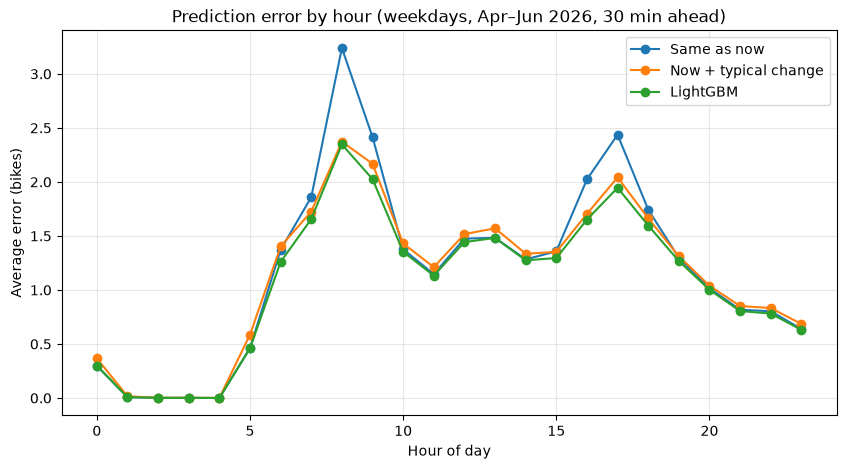

In [6]:
weekday = test[test["dayofweek"] < 5]
by_hour = pd.DataFrame({
    "Same as now": (weekday["pred_same_as_now"] - weekday["bikes_future"]).abs(),
    "Now + typical change": (weekday["pred_now_plus_change"] - weekday["bikes_future"]).abs(),
    "LightGBM": (weekday["pred_lightgbm"] - weekday["bikes_future"]).abs(),
    "hour": weekday["hour"],
}).groupby("hour").mean()

by_hour.plot(figsize=(10, 5), marker="o")
plt.title("Prediction error by hour (weekdays, Apr–Jun 2026, 30 min ahead)")
plt.xlabel("Hour of day")
plt.ylabel("Average error (bikes)")
plt.grid(alpha=0.3)
plt.savefig("../images/model_error_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

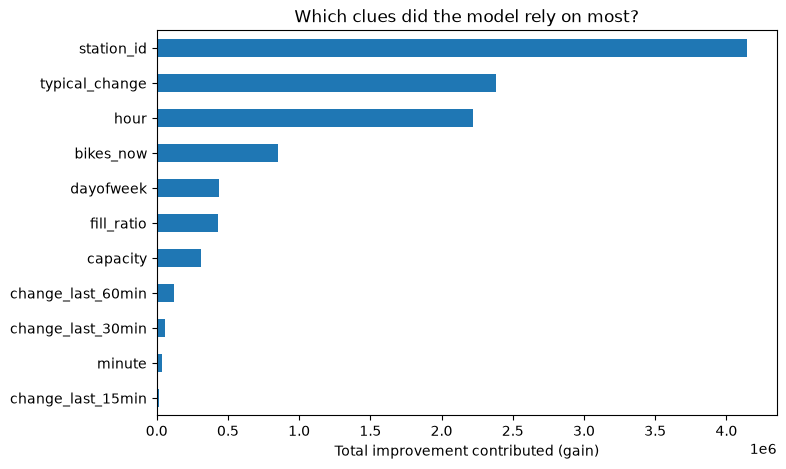

In [7]:
importance = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES).sort_values()
importance.plot.barh(figsize=(8, 5))
plt.title("Which clues did the model rely on most?")
plt.xlabel("Total improvement contributed (gain)")
plt.savefig("../images/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
from pathlib import Path
Path("../models").mkdir(exist_ok=True)
model.booster_.save_model("../models/lightgbm_v1.txt")
print("Saved")

Saved
